# XGBoost: predicting revenue

Datasets (same 6,449 films, same order, same `split`):

| Name | File | Adds |
|---|---|---|
| `people` | `tmdb_combined_85percent.csv` | people lists, top-1,500 people lists |
| `kw` | `movies_with_keyword_embeddings.csv` | keyword embeddings (16) |
| `kw_actor` | `movies_keywords_actors_embedded.csv` | keyword + actor embeddings (16 + 16) |

## 1. Imports

In [1]:
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the data

`index_col=0` reads the leftover `Unnamed: 0` column as the index instead of a feature.

In [2]:
people = pd.read_csv("tmdb_combined_85percent.csv", index_col=0, low_memory=False)
kw = pd.read_csv("movies_with_keyword_embeddings.csv", index_col=0, low_memory=False)
kw_actor = pd.read_csv("movies_keywords_actors_embedded.csv", index_col=0, low_memory=False)

for name, d in [("people", people), ("kw", kw), ("kw_actor", kw_actor)]:
    print(f"{name:9s} {d.shape}")

people    (6449, 55)
kw        (6449, 70)
kw_actor  (6449, 85)


## 3. First rows

In [3]:
people.head()

,id,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,spoken_languages,status,tagline,title,Keywords,cast,crew,revenue_tmdb_2019,orig_split,year,revenue_latest,revenue_source,revenue_ratio,revenue_mismatch,revenue,roi,split,log_budget,log_revenue_tmdb_2019,log_revenue_latest,log_revenue,n_production_companies,n_genres,genre_list,actor,director,producer,writer,editor,camera,visual,sound,actor_85,director_85,producer_85,editor_85,writer_85,sound_85,visual_85,camera_85
0,1,"[{'id': 313576, 'name': 'Hot Tub Tim...",14000000.0,"[{'id': 35, 'name': 'Comedy'}]",NaN,tt2637294,en,Hot Tub Time Machine 2,"When Lou, who has become the ""father...",6.575393,/tQtWuwvMf0hCc2QR2tkolwl7c3c.jpg,"[{'name': 'Paramount Pictures', 'id'...","[{'iso_3166_1': 'US', 'name': 'Unite...",2015-02-20,93.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The Laws of Space and Time are About...,Hot Tub Time Machine 2,"[{'id': 4379, 'name': 'time travel'}...","[{'cast_id': 4, 'character': 'Lou', ...",[{'credit_id': '59ac067c92514107af02...,12314651.0,train,2015.0,13081651.0,imdb_worldwide_gross,1.062284,False,13081651.0,0.934404,train,16.454568,16.326300,16.386721,16.386721,3,1,['Comedy'],"['Rob Corddry', 'Craig Robinson', 'C...","['Kelly Cantley', 'Steve Pink', 'Nic...","['Andrew Panay', 'Adam Blum', 'Rob C...","['Josh Heald', 'Josh Heald']","['Jamie Gross', 'Victoria Rose Samps...","['Declan Quinn', 'Michael Applebaum'...","['Matt Kutcher', 'Rocco Passionino',...","['Christophe Beck', 'Gary C. Bourgeo...","['Rob Corddry', 'Craig Robinson', 'u...","['unknown', 'Steve Pink', 'Nicole Ga...","['Andrew Panay', 'unknown', 'unknown...","['Jamie Gross', 'Victoria Rose Samps...","['Josh Heald', 'Josh Heald']","['Christophe Beck', 'Gary C. Bourgeo...","['Matt Kutcher', 'Rocco Passionino',...","['Declan Quinn', 'Michael Applebaum'..."
1,2,"[{'id': 107674, 'name': 'The Princes...",40000000.0,"[{'id': 35, 'name': 'Comedy'}, {'id'...",NaN,tt0368933,en,The Princess Diaries 2: Royal Engage...,Mia Thermopolis is now a college gra...,8.248895,/w9Z7A0GHEhIp7etpj0vyKOeU1Wx.jpg,"[{'name': 'Walt Disney Pictures', 'i...","[{'iso_3166_1': 'US', 'name': 'Unite...",2004-08-06,113.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,It can take a lifetime to find true ...,The Princess Diaries 2: Royal Engage...,"[{'id': 2505, 'name': 'coronation'},...","[{'cast_id': 1, 'character': 'Mia Th...",[{'credit_id': '52fe43fe9251416c7502...,95149435.0,train,2004.0,134734481.0,imdb_worldwide_gross,1.416030,False,134734481.0,3.368362,train,17.504390,18.370959,18.718817,18.718817,1,4,"['Comedy', 'Drama', 'Family', 'Roman...","['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['Whitney Houston', 'Mario Iscovich'...",['Shonda Rhimes'],['Bruce Green'],['Charles Minsky'],[],['John Debney'],"['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['unknown', 'Mario Iscovich', 'unkno...",['Bruce Green'],['Shonda Rhimes'],['John Debney'],['unknown'],['Charles Minsky']
2,3,NaN,3300000.0,"[{'id': 18, 'name': 'Drama'}]",http://sonyclassics.com/whiplash/,tt2582802,en,Whiplash,Under the direction of a ruthless in...,64.299990,/lIv1QinFqz4dlp5U4lQ6HaiskOZ.jpg,"[{'name': 'Bold Films', 'id': 2266},...","[{'iso_3166_1': 'US', 'name': 'Unite...",2014-10-10,105.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The road to greatness can take you t...,Whiplash,"[{'id': 1416, 'name': 'jazz'}, {'id'...","[{'cast_id': 5, 'character': 'Andrew...",[{'credit_id': '54d5356ec3a3683ba000...,13092000.0,train,2014.0,50360880.0,imdb_worldwide_gross,3.846691,True,50360880.0,15.260873,train,15.009433,16.387512,17.734725,17.734725,3,1,['Drama'],"['Miles Teller', 'J.K. Simmons', 'Me...","['Damien Chazelle', 'Nicolas Duchemi...","['Terri Taylor', 'Jeffrey Stott', 'J...",['Damien Chazelle'],"['Tom Cross', 'Vahe Giragol', 'Joe S...","['Sharone Meir', 'Chris Squires', 'E...","['Jamison

In [4]:
kw.head()

,id,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,spoken_languages,status,tagline,title,cast,crew,revenue_tmdb_2019,orig_split,year,revenue_latest,revenue_source,revenue_ratio,revenue_mismatch,revenue,roi,split,log_budget,log_revenue_tmdb_2019,log_revenue_latest,log_revenue,n_production_companies,n_genres,genre_list,actor,director,producer,writer,editor,camera,visual,sound,actor_85,director_85,producer_85,editor_85,writer_85,sound_85,visual_85,camera_85,keyword_emb_0,keyword_emb_1,keyword_emb_2,keyword_emb_3,keyword_emb_4,keyword_emb_5,keyword_emb_6,keyword_emb_7,keyword_emb_8,keyword_emb_9,keyword_emb_10,keyword_emb_11,keyword_emb_12,keyword_emb_13,keyword_emb_14,keyword_emb_15
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,"[{'id': 313576, 'name': 'Hot Tub Tim...",14000000.0,"[{'id': 35, 'name': 'Comedy'}]",NaN,tt2637294,en,Hot Tub Time Machine 2,"When Lou, who has become the ""father...",6.575393,/tQtWuwvMf0hCc2QR2tkolwl7c3c.jpg,"[{'name': 'Paramount Pictures', 'id'...","[{'iso_3166_1': 'US', 'name': 'Unite...",2015-02-20,93.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The Laws of Space and Time are About...,Hot Tub Time Machine 2,"[{'cast_id': 4, 'character': 'Lou', ...",[{'credit_id': '59ac067c92514107af02...,12314651.0,train,2015.0,13081651.0,imdb_worldwide_gross,1.062284,False,13081651.0,0.934404,train,16.454568,16.326300,16.386721,16.386721,3,1,['Comedy'],"['Rob Corddry', 'Craig Robinson', 'C...","['Kelly Cantley', 'Steve Pink', 'Nic...","['Andrew Panay', 'Adam Blum', 'Rob C...","['Josh Heald', 'Josh Heald']","['Jamie Gross', 'Victoria Rose Samps...","['Declan Quinn', 'Michael Applebaum'...","['Matt Kutcher', 'Rocco Passionino',...","['Christophe Beck', 'Gary C. Bourgeo...","['Rob Corddry', 'Craig Robinson', 'u...","['unknown', 'Steve Pink', 'Nicole Ga...","['Andrew Panay', 'unknown', 'unknown...","['Jamie Gross', 'Victoria Rose Samps...","['Josh Heald', 'Josh Heald']","['Christophe Beck', 'Gary C. Bourgeo...","['Matt Kutcher', 'Rocco Passionino',...","['Declan Quinn', 'Michael Applebaum'...",-1.777749,0.637014,-0.516788,-0.452637,-0.214039,-0.025243,0.112537,-1.007099,-0.568484,-0.493513,-0.583122,-0.364566,0.305692,-0.329762,1.012384,0.308929
1,2,"[{'id': 107674, 'name': 'The Princes...",40000000.0,"[{'id': 35, 'name': 'Comedy'}, {'id'...",NaN,tt0368933,en,The Princess Diaries 2: Royal Engage...,Mia Thermopolis is now a college gra...,8.248895,/w9Z7A0GHEhIp7etpj0vyKOeU1Wx.jpg,"[{'name': 'Walt Disney Pictures', 'i...","[{'iso_3166_1': 'US', 'name': 'Unite...",2004-08-06,113.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,It can take a lifetime to find true ...,The Princess Diaries 2: Royal Engage...,"[{'cast_id': 1, 'character': 'Mia Th...",[{'credit_id': '52fe43fe9251416c7502...,95149435.0,train,2004.0,134734481.0,imdb_worldwide_gross,1.416030,False,134734481.0,3.368362,train,17.504390,18.370959,18.718817,18.718817,1,4,"['Comedy', 'Drama', 'Family', 'Roman...","['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['Whitney Houston', 'Mario Iscovich'...",['Shonda Rhimes'],['Bruce Green'],['Charles Minsky'],[],['John Debney'],"['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['unknown', 'Mario Iscovich', 'unkno...",['Bruce Green'],['Shonda Rhimes'],['John Debney'],['unknown'],['Charles Minsky'],-0.953154,0.005439,-0.105866,-0.011056,0.352466,-0.512716,-0.881608,0.074226,-1.207549,-0.691957,-0.162372,0.603635,-0.513912,-0.232688,0.378878,0.267959
2,3,NaN,3300000.0,"[{'id': 18, 'name': 'Drama'}]",http://sonyclassics.com/whiplash/,tt2582802,en,Whiplash,Under the direction of a ruthless in...,64.299990,/lIv1QinFqz4dlp5U4lQ6HaiskOZ.jpg,"[{'name': 'Bold Films', 'id': 2266},...","[{'iso_3166_1': 'US', 'name': 'Unite...",2014-10-10,105.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The road to greatness can take you t.

In [5]:
kw_actor.head()

,id,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,spoken_languages,status,tagline,title,cast,crew,revenue_tmdb_2019,orig_split,year,revenue_latest,revenue_source,revenue_ratio,revenue_mismatch,revenue,roi,split,log_budget,log_revenue_tmdb_2019,log_revenue_latest,log_revenue,n_production_companies,n_genres,genre_list,director,producer,writer,editor,camera,visual,sound,actor_85,director_85,producer_85,editor_85,writer_85,sound_85,visual_85,camera_85,keyword_emb_0,keyword_emb_1,keyword_emb_2,keyword_emb_3,keyword_emb_4,keyword_emb_5,keyword_emb_6,keyword_emb_7,keyword_emb_8,keyword_emb_9,keyword_emb_10,keyword_emb_11,keyword_emb_12,keyword_emb_13,keyword_emb_14,keyword_emb_15,actor_emb_0,actor_emb_1,actor_emb_2,actor_emb_3,actor_emb_4,actor_emb_5,actor_emb_6,actor_emb_7,actor_emb_8,actor_emb_9,actor_emb_10,actor_emb_11,actor_emb_12,actor_emb_13,actor_emb_14,actor_emb_15
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,"[{'id': 313576, 'name': 'Hot Tub Tim...",14000000.0,"[{'id': 35, 'name': 'Comedy'}]",NaN,tt2637294,en,Hot Tub Time Machine 2,"When Lou, who has become the ""father...",6.575393,/tQtWuwvMf0hCc2QR2tkolwl7c3c.jpg,"[{'name': 'Paramount Pictures', 'id'...","[{'iso_3166_1': 'US', 'name': 'Unite...",2015-02-20,93.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,The Laws of Space and Time are About...,Hot Tub Time Machine 2,"[{'cast_id': 4, 'character': 'Lou', ...",[{'credit_id': '59ac067c92514107af02...,12314651.0,train,2015.0,13081651.0,imdb_worldwide_gross,1.062284,False,13081651.0,0.934404,train,16.454568,16.326300,16.386721,16.386721,3,1,['Comedy'],"['Kelly Cantley', 'Steve Pink', 'Nic...","['Andrew Panay', 'Adam Blum', 'Rob C...","['Josh Heald', 'Josh Heald']","['Jamie Gross', 'Victoria Rose Samps...","['Declan Quinn', 'Michael Applebaum'...","['Matt Kutcher', 'Rocco Passionino',...","['Christophe Beck', 'Gary C. Bourgeo...","['Rob Corddry', 'Craig Robinson', 'u...","['unknown', 'Steve Pink', 'Nicole Ga...","['Andrew Panay', 'unknown', 'unknown...","['Jamie Gross', 'Victoria Rose Samps...","['Josh Heald', 'Josh Heald']","['Christophe Beck', 'Gary C. Bourgeo...","['Matt Kutcher', 'Rocco Passionino',...","['Declan Quinn', 'Michael Applebaum'...",0.418321,-0.676433,-0.380568,0.560362,-0.358408,-0.726957,-0.193744,-0.550035,0.010656,-0.752646,0.940972,0.275916,-0.312099,0.556656,0.320231,0.590081,0.125004,0.277118,0.145052,0.313681,-0.199879,-0.428751,0.333732,0.221092,-0.134486,-0.015146,-0.218744,-0.410835,0.188762,-0.092167,-0.015582,0.082448
1,2,"[{'id': 107674, 'name': 'The Princes...",40000000.0,"[{'id': 35, 'name': 'Comedy'}, {'id'...",NaN,tt0368933,en,The Princess Diaries 2: Royal Engage...,Mia Thermopolis is now a college gra...,8.248895,/w9Z7A0GHEhIp7etpj0vyKOeU1Wx.jpg,"[{'name': 'Walt Disney Pictures', 'i...","[{'iso_3166_1': 'US', 'name': 'Unite...",2004-08-06,113.0,"[{'iso_639_1': 'en', 'name': 'Englis...",Released,It can take a lifetime to find true ...,The Princess Diaries 2: Royal Engage...,"[{'cast_id': 1, 'character': 'Mia Th...",[{'credit_id': '52fe43fe9251416c7502...,95149435.0,train,2004.0,134734481.0,imdb_worldwide_gross,1.416030,False,134734481.0,3.368362,train,17.504390,18.370959,18.718817,18.718817,1,4,"['Comedy', 'Drama', 'Family', 'Roman...",['Garry Marshall'],"['Whitney Houston', 'Mario Iscovich'...",['Shonda Rhimes'],['Bruce Green'],['Charles Minsky'],[],['John Debney'],"['Anne Hathaway', 'Julie Andrews', '...",['Garry Marshall'],"['unknown', 'Mario Iscovich', 'unkno...",['Bruce Green'],['Shonda Rhimes'],['John Debney'],['unknown'],['Charles Minsky'],0.387903,-0.119911,-0.229503,-0.335210,0.283421,-0.050111,-0.677718,-0.695790,0.471635,0.814337,-0.197410,0.353637,0.122059,-0.060604,-0.422948,-0.138103,0.301756,0.304467,-0.030553,0.311244,-0.018765,-0.015841,0.093359,-0.108886,0.292908,0.210057,-0.420907,-0

## 4. Combine

The files hold the same films in the same order. `people` is the base; the keyword and actor embeddings come from `kw_actor` (its keyword embeddings are the newer version, so `kw` adds nothing).

In [6]:
emb_cols = [c for c in kw_actor.columns if c.startswith(("keyword_emb", "actor_emb"))]
df = people.merge(kw_actor[["imdb_id"] + emb_cols], on="imdb_id", how="left", validate="1:1")

assert len(df) == len(people)
print(df.shape)

(6449, 87)


## 5. Build features

Columns that contain or are computed from revenue are **never** features: `revenue*`, `log_revenue*`, `roi`, `revenue_ratio`, `revenue_mismatch`, `revenue_source`.

The list columns are stored as text such as `"['Comedy']"`; `ast.literal_eval` turns them into Python lists.

In [7]:
def parse(s):
    if not isinstance(s, str):
        return []
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return []


F = pd.DataFrame(index=df.index)

# Numeric (NaN left as NaN: XGBoost handles missing values itself)
F["log_budget"] = df["log_budget"]
F["runtime"] = df["runtime"].replace(0, np.nan)
F["year"] = df["year"]
F["log_popularity"] = np.log1p(df["popularity"])
F["n_genres"] = df["n_genres"]
F["n_production_companies"] = df["n_production_companies"]

# Release date
date = pd.to_datetime(df["release_date"], errors="coerce")
F["month"] = date.dt.month
F["weekday"] = date.dt.dayofweek

# Counts from the JSON-like columns
for col, new in [("cast", "n_cast"), ("crew", "n_crew"), ("Keywords", "n_keywords"),
                 ("production_countries", "n_countries"), ("spoken_languages", "n_languages")]:
    F[new] = df[col].map(parse).str.len()

# Flags
F["has_collection"] = df["belongs_to_collection"].notna().astype(int)
F["has_homepage"] = df["homepage"].notna().astype(int)
F["has_tagline"] = df["tagline"].notna().astype(int)
F["has_keywords"] = (F["n_keywords"] > 0).astype(int)

F.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_budget,4755.0,16.63,1.42,9.21,15.89,16.81,17.62,19.76
runtime,6447.0,108.06,19.51,46.00,95.00,104.00,118.00,254.00
year,6449.0,2000.79,13.11,1921.00,1993.00,2004.00,2011.00,2017.00
log_popularity,6449.0,2.09,0.68,0.00,1.80,2.19,2.51,6.31
n_genres,6449.0,2.52,1.12,0.00,2.00,2.00,3.00,8.00
n_production_companies,6449.0,2.89,2.22,0.00,1.00,2.00,4.00,26.00
month,6449.0,6.87,3.37,1.00,4.00,7.00,10.00,12.00
weekday,6449.0,3.27,1.31,0.00,2.00,4.00,4.00,6.00
n_cast,6449.0,21.79,17.87,0.00,12.00,17.00,25.00,165.00
n_crew,6449.0,26.20,29.29,0.00,9.00,16.00,31.00,194.00


**Categoricals.** Original language and main production country: the 8 most common values in the **train** split get a 0/1 column each; everything else falls into "other".

**Genres.** One 0/1 column per genre (a film can have several).

In [8]:
is_train = df["split"] == "train"


def one_hot_top(values, prefix, k=8):
    top = values[is_train].value_counts().index[:k]
    out = pd.get_dummies(values.where(values.isin(top), "other"), prefix=prefix, dtype=int)
    return out


country_main = df["production_countries"].map(parse).map(lambda L: L[0]["iso_3166_1"] if L else "none")
cat = pd.concat([one_hot_top(df["original_language"], "lang"),
                 one_hot_top(country_main, "country")], axis=1)

genres = df["genre_list"].map(parse)
genre = pd.get_dummies(genres.explode()).groupby(level=0).max().reindex(df.index, fill_value=0).astype(int)
genre.columns = ["genre_" + c.replace(" ", "_") for c in genre.columns]

print(f"categorical columns: {cat.shape[1]}   genre columns: {genre.shape[1]}")

categorical columns: 18   genre columns: 19


**People counts.** For each role, the number of names in the top-1,500 list (i.e. not `unknown`). A film full of well-known people scores high.

In [9]:
roles = ["actor", "director", "producer", "writer", "editor", "camera", "visual", "sound"]

people_counts = pd.DataFrame(index=df.index)
for r in roles:
    people_counts[f"n_known_{r}"] = df[f"{r}_85"].map(parse).map(lambda L: sum(x != "unknown" for x in L))

people_counts.describe().T[["mean", "50%", "max"]].round(1)

,mean,50%,max
n_known_actor,4.5,4.0,36.0
n_known_director,1.1,1.0,13.0
n_known_producer,2.6,2.0,18.0
n_known_writer,1.1,1.0,10.0
n_known_editor,1.2,1.0,14.0
n_known_camera,1.4,1.0,18.0
n_known_visual,0.8,0.0,38.0
n_known_sound,2.2,1.0,30.0


## 6. Feature sets

Each set adds one group, so the results show what each group is worth.

In [10]:
base_cols = list(F.columns)
kw_cols = [c for c in emb_cols if c.startswith("keyword_emb")]
actor_cols = [c for c in emb_cols if c.startswith("actor_emb")]

X_all = pd.concat([F, cat, genre, people_counts, df[emb_cols]], axis=1)

feature_sets = {
    "A: base":                  base_cols + list(cat.columns) + list(genre.columns),
    "B: + people counts":       base_cols + list(cat.columns) + list(genre.columns) + list(people_counts.columns),
}
feature_sets["C: + keyword emb"] = feature_sets["B: + people counts"] + kw_cols
feature_sets["D: + actor emb"] = feature_sets["C: + keyword emb"] + actor_cols

for name, cols in feature_sets.items():
    print(f"{name:22s} {len(cols):3d} features")

A: base                 54 features
B: + people counts      62 features
C: + keyword emb        78 features
D: + actor emb          94 features


## 7. Train, validation and test

Target: `log_revenue` = ln(1 + revenue). The `split` column from the combine notebook is used as is: models are fitted on **train**, early-stopped and compared on **val**; **test** is used once, at the end.

In [11]:
y = df["log_revenue"]
tr, va, te = (df["split"] == s for s in ["train", "val", "test"])
print(f"train {tr.sum():,}   val {va.sum():,}   test {te.sum():,}")

train 4,514   val 967   test 968


### Linear regression baseline

Same features as set A. Missing values are filled with the training median (plus a missing-value indicator), and features are standardised. This is the model the README asks to beat by 20%.

In [12]:
def scores(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


lin = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())
cols_A = feature_sets["A: base"]
lin.fit(X_all.loc[tr, cols_A], y[tr])

results = {"Linear regression (A)": scores(y[va], lin.predict(X_all.loc[va, cols_A]))}
pd.DataFrame(results).T.round(3)

,RMSE,MAE,R2
Linear regression (A),1.524,1.133,0.572


### XGBoost on each feature set

The same hyperparameters for every set, so the comparison is about features. Training stops when validation RMSE has not improved for 100 rounds.

In [13]:
params = dict(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    early_stopping_rounds=100,
    eval_metric="rmse",
    random_state=42,
)

models = {}
for name, cols in feature_sets.items():
    m = xgb.XGBRegressor(**params)
    m.fit(X_all.loc[tr, cols], y[tr], eval_set=[(X_all.loc[va, cols], y[va])], verbose=False)
    models[name] = m
    results[f"XGBoost {name}"] = scores(y[va], m.predict(X_all.loc[va, cols])) | {"trees": m.best_iteration + 1}

res = pd.DataFrame(results).T
lin_rmse = res.loc["Linear regression (A)", "RMSE"]
res["RMSE vs linear"] = (1 - res["RMSE"] / lin_rmse).map("{:+.1%}".format)
res.round(3)

,RMSE,MAE,R2,trees,RMSE vs linear
Linear regression (A),1.524,1.133,0.572,NaN,+0.0%
XGBoost A: base,1.351,0.994,0.663,524.0,+11.3%
XGBoost B: + people counts,1.314,0.965,0.682,504.0,+13.7%
XGBoost C: + keyword emb,1.323,0.985,0.677,424.0,+13.1%
XGBoost D: + actor emb,1.353,1.002,0.662,327.0,+11.2%


RMSE, MAE and R² are on the validation set, in units of ln(revenue). `RMSE vs linear` is the reduction in RMSE relative to linear regression; the README target is +20%.

## 8. Best model: feature importance

Best on validation: B: + people counts


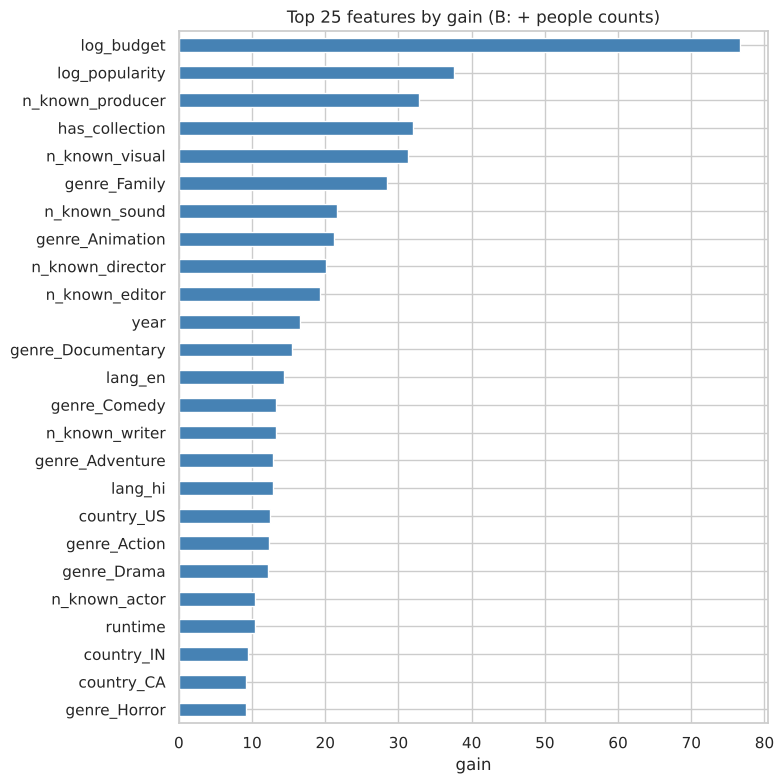

In [14]:
best_name = res.drop(index="Linear regression (A)")["RMSE"].astype(float).idxmin().replace("XGBoost ", "")
best = models[best_name]
print("Best on validation:", best_name)

imp = pd.Series(best.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(8, 8))
imp[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("gain")
ax.set_title(f"Top 25 features by gain ({best_name})")
plt.tight_layout()

## 9. Test set (used once)

The best model and the linear baseline, scored on the held-out test films.

In [15]:
cols_best = feature_sets[best_name]
test_res = pd.DataFrame({
    "Linear regression (A)": scores(y[te], lin.predict(X_all.loc[te, cols_A])),
    f"XGBoost {best_name}": scores(y[te], best.predict(X_all.loc[te, cols_best])),
}).T
test_res["RMSE vs linear"] = (1 - test_res["RMSE"] / test_res.loc["Linear regression (A)", "RMSE"]).map("{:+.1%}".format)
test_res.round(3)

,RMSE,MAE,R2,RMSE vs linear
Linear regression (A),1.517,1.161,0.563,+0.0%
XGBoost B: + people counts,1.313,0.974,0.673,+13.5%


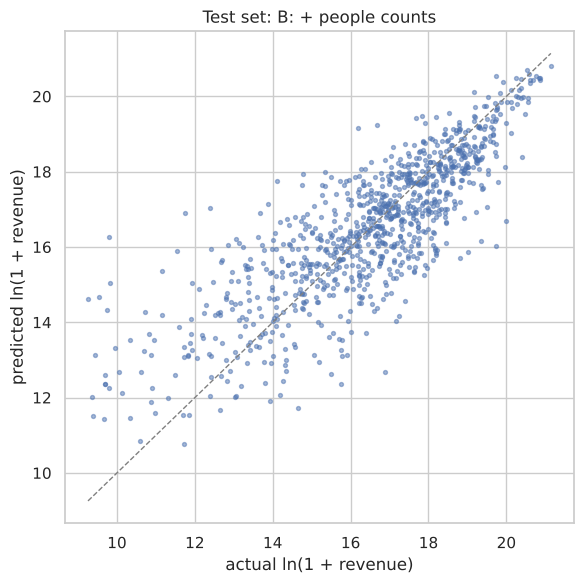

In [16]:
pred = best.predict(X_all.loc[te, cols_best])
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y[te], pred, s=8, alpha=0.5)
lims = [min(y[te].min(), pred.min()), max(y[te].max(), pred.max())]
ax.plot(lims, lims, color="gray", ls="--", lw=1)
ax.set_xlabel("actual ln(1 + revenue)")
ax.set_ylabel("predicted ln(1 + revenue)")
ax.set_title(f"Test set: {best_name}")
plt.tight_layout()